# Deliverable 4: Predicting the Trunk Diameter, Regression

**MOD10 Introduction to Machine Learning**, November 2026

- **Group:** CUPILLARD Eliot, DENOUAL Romain, ROY-NOUGUIER Erwann
- **Dataset:** Arbres publics sur le territoire de la Ville (consolidated file), City of Montreal, licence CC BY 4.0, same unchanged copy as Deliverable 2 (https://doi.org/10.5281/zenodo.23540888)
- **Target (`y`):** `DHP`, the trunk diameter at 1.4 m (a number)
- **Question:** Can we predict the trunk diameter of a public tree from its species, location and age?

## 0. Setup and data from Deliverable 2

We reuse the data saved at the end of Deliverable 2 (`data/processed/trees_encoded.csv`): cleaned and encoded, not scaled. We do not clean or encode again. The file comes from the `to_csv` line of section 3 of that notebook and is kept in the repository.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_PATH = Path("../data/processed/trees_encoded.csv")

assert DATA_PATH.is_file(), "File missing: run Deliverable 2 with the to_csv line of section 3 not commented"
data = pd.read_csv(DATA_PATH, index_col="raw_row")
assert data.shape == (334950, 62), "Wrong shape: this is not the file of Deliverable 2"

print("Data:", data.shape, "| Missing values:", data.isna().sum().sum())

Data: (334950, 62) | Missing values: 0


## 1. Our target

We predict `DHP`, the trunk diameter at 1.4 m. It is our real target since Deliverable 1, and it is a number, so no derived category this time.

From Deliverable 2: the unit is not given, 27% of the trees have a DHP of exactly 5 (probably a default value), and a few trees are very large (up to 246).

In [2]:
data["DHP"].agg(["mean", "median", "min", "max"]).round(2)

mean       25.24
median     19.00
min         1.00
max       246.00
Name: DHP, dtype: float64

## 2. Features and target

`y` is `DHP` and `X` is the rest. The identifiers and names were removed in Deliverable 2.

In [3]:
X = data.drop(columns=["DHP"])
y = data["DHP"]
print("X:", X.shape, "| y:", y.shape)

X: (334950, 61) | y: (334950,)


## 3. Split and scale

Same split as Deliverables 2 and 3 (`test_size=0.2`, `random_state=SEED`), so the same rows. The Deliverable 2 file is saved before the split, so we split and scale again here.

KNN needs scaling, linear regression does not. We scale the same three columns as before, with the scaler fitted on the train set only, and we use this data for both models. Scaling does not change the linear predictions.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

columns_to_scale = ["Latitude", "Longitude", "age"]
scaler = StandardScaler()
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Mean and standard deviation after scaling:")
display(X_train[columns_to_scale].agg(["mean", "std"]).round(3))
display(X_test[columns_to_scale].agg(["mean", "std"]).round(3))

Train: (267960, 61) | Test: (66990, 61)
Mean and standard deviation after scaling:


,Latitude,Longitude,age
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0


,Latitude,Longitude,age
mean,0.003,0.003,-0.004
std,0.998,0.998,0.994


## 4. Train

Linear regression: in each group of 0/1 columns (borough, place, species), the columns always add up to 1. So, as with `drop_first=True` in class, we remove one column per group for this model. The predictions do not change, and each coefficient reads as a difference with the removed column.

KNN regression: it predicts the mean DHP of the k closest trees. As in Deliverable 3, we choose k on a validation set (20% of the train set). The test set is only used at the end.

In [5]:
reference_columns = ["ARROND_NOM_Ahuntsic - Cartierville", "Emplacement_Banquette Aménagée", "Essence_latin_Other"]
X_train_lin = X_train.drop(columns=reference_columns)
X_test_lin = X_test.drop(columns=reference_columns)

linear = LinearRegression()
linear.fit(X_train_lin, y_train)
print("Intercept:", round(linear.intercept_, 2), "| Coefficients:", len(linear.coef_))

Intercept: 4.59 | Coefficients: 58


In [6]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
print("Fit:", X_fit.shape, "| Validation:", X_val.shape)

for k in [1, 5, 9, 15, 51, 151, 517]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_fit, y_fit)
    r2 = r2_score(y_val, knn.predict(X_val))
    print(f"k={k} | R²={r2:.4f}")

Fit: (214368, 61) | Validation: (53592, 61)


k=1 | R²=0.6725


k=5 | R²=0.7569


k=9 | R²=0.7528


k=15 | R²=0.7412


k=51 | R²=0.7030


k=151 | R²=0.6697


k=517 | R²=0.6217


| k | 1 | 5 | 9 | 15 | 51 | 151 | 517 |
|---|---|---|---|---|---|---|---|
| R² on the validation set | 0.6725 | 0.7569 | 0.7528 | 0.7412 | 0.7030 | 0.6697 | 0.6217 |

We keep k = 5, the best R². Unlike Deliverable 3, k = 1 is clearly worse here (0.6725): to predict a number, the mean of 5 trees is more stable than one single tree.

## 5. Evaluation

We train KNN on the whole train set with the chosen k, then we test each model once. The baseline always predicts the mean DHP of the train set. RMSE is the square root of MSE, in DHP units.

In [7]:
best_k = 5
knn = KNeighborsRegressor(n_neighbors=best_k)
knn.fit(X_train, y_train)

baseline_preds = np.full(len(y_test), y_train.mean())
linear_preds = linear.predict(X_test_lin)
knn_preds = knn.predict(X_test)

for name, preds in [("Baseline (mean)", baseline_preds), ("Linear regression", linear_preds), ("KNN regression", knn_preds)]:
    mse = mean_squared_error(y_test, preds)
    print(f"{name} | MSE: {mse:.1f} | RMSE: {mse ** 0.5:.2f} | R²: {r2_score(y_test, preds):.4f}")

Baseline (mean) | MSE: 490.1 | RMSE: 22.14 | R²: -0.0000
Linear regression | MSE: 193.6 | RMSE: 13.91 | R²: 0.6050
KNN regression | MSE: 113.4 | RMSE: 10.65 | R²: 0.7687


## 6. Interpretation

The linear regression has R² = 0.605: it explains about 60% of the variation of DHP. Its typical error (RMSE) is about 14, against 22 for the baseline.

KNN does better on this split: R² = 0.769, with a typical error of about 11. The baseline has R² = 0, as expected.

Residuals of the linear regression (real minus predicted), as in class:

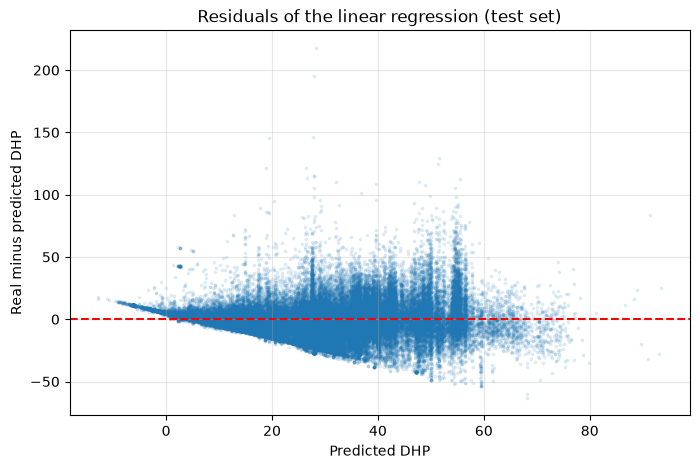

Negative predictions of the linear regression: 1372 of 66990


In [8]:
residuals = y_test - linear_preds

plt.figure(figsize=(8, 5))
plt.scatter(linear_preds, residuals, s=3, alpha=0.1)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals of the linear regression (test set)")
plt.xlabel("Predicted DHP")
plt.ylabel("Real minus predicted DHP")
plt.grid(True, alpha=0.3)
plt.show()

print("Negative predictions of the linear regression:", (linear_preds < 0).sum(), "of", len(linear_preds))

The residuals are not a shapeless cloud:

- the errors grow with the predicted DHP (the cloud opens to the right);
- the straight edge at the bottom comes from DHP never going below 1;
- 1,372 test trees (2%) get a negative DHP, which is impossible.

A line gets the main trend, but not the full shape of the data.

Coefficients of the linear regression, in DHP units. For `Latitude`, `Longitude` and `age`, it is the change for one standard deviation. For a 0/1 column, it is the difference with the removed column of its group.

In [9]:
coefficients = pd.Series(linear.coef_, index=X_train_lin.columns).sort_values()
print(coefficients[["age", "age_missing", "Latitude", "Longitude", "INV_TYPE", "Arbre_remarquable"]].round(2))
print()
print("Smallest:")
print(coefficients.head(3).round(2))
print()
print("Largest:")
print(coefficients.tail(3).round(2))

age                   9.75
age_missing          23.26
Latitude              0.83
Longitude            -0.37
INV_TYPE              5.55
Arbre_remarquable    38.89
dtype: float64

Smallest:
ARROND_NOM_Verdun                  -7.66
Essence_latin_pinus sylvestris     -5.47
Essence_latin_syringa reticulata   -4.87
dtype: float64

Largest:
age_missing                        23.26
Essence_latin_populus deltoides    23.50
Arbre_remarquable                  38.89
dtype: float64


- `age`: +9.75 for one standard deviation (about 13 years). Older trees are bigger, as expected.
- `age_missing`: +23.26. Trees with no planting date are bigger, as seen in Deliverable 2.
- `Arbre_remarquable`: +38.89. Remarkable trees are much bigger (only 157 trees, so this number is less sure).
- `INV_TYPE`: +5.55 for street trees compared with park trees.
- `Latitude` and `Longitude` count little (less than 1).
- Species matter: `populus deltoides` (a poplar) is +23.50 compared with `Other`, `syringa reticulata` (a small tree) is −4.87.

Each coefficient is "with everything else equal", and some features are linked, so we read them as trends, not exact effects.

Deliverable 3 showed that a random split puts trees of the same street in train and test. Here, for each borough, we train on the 12 others and predict 2,000 trees of that borough. Then we compute one R² on all these predictions. The borough columns are not used here.

In [10]:
borough_columns = [c for c in X.columns if c.startswith("ARROND_NOM_")]
X_no_borough = X.drop(columns=borough_columns)
real, pred_baseline, pred_linear, pred_knn = [], [], [], []

for column in borough_columns:
    inside = X[column] == 1
    X_tr = X_no_borough[~inside].copy()
    X_te = X_no_borough[inside].sample(2000, random_state=SEED).copy()
    y_tr = y[~inside]
    y_te = y.loc[X_te.index]

    scaler_b = StandardScaler()
    X_tr[columns_to_scale] = scaler_b.fit_transform(X_tr[columns_to_scale])
    X_te[columns_to_scale] = scaler_b.transform(X_te[columns_to_scale])

    real.extend(y_te)
    pred_baseline.extend(np.full(len(y_te), y_tr.mean()))
    pred_linear.extend(LinearRegression().fit(X_tr, y_tr).predict(X_te))
    pred_knn.extend(KNeighborsRegressor(n_neighbors=best_k).fit(X_tr, y_tr).predict(X_te))

print("Trees predicted:", len(real))
for name, preds in [("Baseline (mean)", pred_baseline), ("Linear regression", pred_linear), ("KNN regression", pred_knn)]:
    print(f"{name} | R² on unseen boroughs: {r2_score(real, preds):.4f}")

Trees predicted: 26000
Baseline (mean) | R² on unseen boroughs: -0.0053
Linear regression | R² on unseen boroughs: 0.5060
KNN regression | R² on unseen boroughs: 0.3454


On unseen boroughs, the order changes: the linear regression keeps R² = 0.506, but KNN falls to 0.345. As in Deliverable 3, KNN was helped by nearby trees of the same street on the random split. The linear regression learns general trends (age, species, type of place), so it holds better on a new area.

## 7. Model fit

Regression suits our project, since DHP is a number. KNN wins on the random split (R² 0.769 against 0.605), but the linear regression wins on unseen boroughs (0.506 against 0.345), is much faster and can be read, so we prefer it.